**ФИО студента**: Никишина Елизавета Владиславовна

**Группа**: S4102

**Список выполненных пунктов задания**: все пункты

In [1]:
import warnings
warnings.filterwarnings("ignore")

try:
    import torch_geometric
except ImportError:
    !pip install -q torch_geometric

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
from torch_geometric.datasets import Planetoid
from torch_geometric.nn import GCNConv
from torch_geometric.utils import add_self_loops, degree, to_undirected
from torch_geometric.utils import add_remaining_self_loops
from torch_geometric.utils import subgraph

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("устройство:", device)

устройство: cuda


## **Домашнее задание 1. Message passing своими руками**

### **Часть 1. Реализация и проверка**

- Реализуйте MyGCNConv — слой GCN из лекции 3, через scatter-операции.
- Реализуйте MySAGEConv — mean-агрегация соседей плюс отдельная матрица для собственного вектора вершины (без петель).
- Положите оба класса в submission.py и прогоните автотесты:

```
pip install pytest torch torch_geometric
pytest tests/test_task1.py -v
```
- Приложите вывод тестов в ноутбук.

Тесты проверяют совпадение с GCNConv и SAGEConv из PyG при одинаковых весах, инвариантность к перенумерации вершин, поведение на направленном графе и на вершинах без соседей.

In [3]:
class MyGCNConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        n = x.size(0)
        # петли и нормировка
        edge_index, _ = add_remaining_self_loops(edge_index, num_nodes=n)
        row, col = edge_index
        deg = degree(col, n, dtype=x.dtype).clamp(min=1)
        # [n, out_dim]
        h = self.lin(x)

        norm = deg[row].pow(-0.5) * deg[col].pow(-0.5)

        # message + aggregate
        msg = h[row] * norm.unsqueeze(-1)

        out = torch.zeros_like(h)

        return out.index_add_(0, col, msg)

In [4]:
class MySAGEConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin_neigh = nn.Linear(in_dim, out_dim, bias=False)
        self.lin_self = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        n = x.size(0)
        row, col = edge_index

        # суммируем признаки соседей
        neigh_sum = torch.zeros_like(x)
        neigh_sum.index_add_(0, col, x[row])

        # число входящих соседей каждой вершины
        deg = degree(col, n, dtype=x.dtype).clamp(min=1)

        # среднее признаков соседей
        neigh_mean = neigh_sum / deg.unsqueeze(-1)

        out = self.lin_neigh(neigh_mean) + self.lin_self(x)

        return out

In [5]:
%%writefile submission.py

import torch
from torch import nn
from torch_geometric.utils import degree, add_remaining_self_loops

class MyGCNConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        n = x.size(0)
        # петли и нормировка
        edge_index, _ = add_remaining_self_loops(edge_index, num_nodes=n)
        row, col = edge_index
        deg = degree(col, n, dtype=x.dtype).clamp(min=1)
        # [n, out_dim]
        h = self.lin(x)

        norm = deg[row].pow(-0.5) * deg[col].pow(-0.5)

        # message + aggregate
        msg = h[row] * norm.unsqueeze(-1)

        out = torch.zeros_like(h)

        return out.index_add_(0, col, msg)

class MySAGEConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.lin_neigh = nn.Linear(in_dim, out_dim, bias=False)
        self.lin_self = nn.Linear(in_dim, out_dim, bias=False)

    def forward(self, x, edge_index):
        n = x.size(0)
        row, col = edge_index

        # суммируем признаки соседей
        neigh_sum = torch.zeros_like(x)
        neigh_sum.index_add_(0, col, x[row])

        # число входящих соседей каждой вершины
        deg = degree(col, n, dtype=x.dtype).clamp(min=1)

        # среднее признаков соседей
        neigh_mean = neigh_sum / deg.unsqueeze(-1)

        out = self.lin_neigh(neigh_mean) + self.lin_self(x)

        return out

Writing submission.py


In [6]:
!python -m pytest tests/test_task1.py -v

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content
plugins: langsmith-0.14.11, anyio-4.15.1, typeguard-4.6.0, platformdirs-4.13.5
collected 7 items                                                              

tests/test_task1.py::test_gcn_output_shape PASSED                        [ 14%]
tests/test_task1.py::test_gcn_matches_pyg PASSED                         [ 28%]
tests/test_task1.py::test_gcn_on_directed_graph PASSED                   [ 42%]
tests/test_task1.py::test_gcn_permutation_invariance PASSED              [ 57%]
tests/test_task1.py::test_gcn_isolated_node_is_finite PASSED             [ 71%]
tests/test_task1.py::test_sage_matches_pyg PASSED                        [ 85%]
tests/test_task1.py::test_gcn_is_trainable PASSED                        [100%]

============================== 7 passed in 6.42s ==========================

### **Часть 2. Воспроизведение результата**

 - Обучите двухслойную модель на своих слоях на Cora и CiteSeer, стандартный сплит Planetoid.
- Каждый замер — не менее 5 запусков с разными сидами, в отчёте среднее и стандартное отклонение.
- Сравните с числами из статьи Kipf & Welling (2017): Cora 81.5, CiteSeer 70.3. Попадание в ± 2 процентных пункта считается воспроизведением.
- Обязательный baseline: MLP того же размера, который не видит графа. Насколько граф улучшает результат на каждом датасете?

In [7]:
dataset_cora = Planetoid(root="/tmp/Cora", name="Cora", split="public")
data_cora = dataset_cora[0]

# ребра храним в обе стороны
data_cora.edge_index = to_undirected(data_cora.edge_index)
data_cora = data_cora.to(device)
print(data_cora)
print(f"размечено: train {int(data_cora.train_mask.sum())}, "
      f"val {int(data_cora.val_mask.sum())}, "
      f"test {int(data_cora.test_mask.sum())}")

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
размечено: train 140, val 500, test 1000


In [8]:
dataset_citeseer = Planetoid(root="/tmp/CiteSeer", name="CiteSeer", split="public")
data_citeseer = dataset_citeseer[0]

# ребра храним в обе стороны
data_citeseer.edge_index = to_undirected(data_citeseer.edge_index)
data_citeseer = data_citeseer.to(device)
print(data_citeseer)
print(f"размечено: train {int(data_citeseer.train_mask.sum())}, "
      f"val {int(data_citeseer.val_mask.sum())}, "
      f"test {int(data_citeseer.test_mask.sum())}")

Data(x=[3327, 3703], edge_index=[2, 9104], y=[3327], train_mask=[3327], val_mask=[3327], test_mask=[3327])
размечено: train 120, val 500, test 1000


In [9]:
class GNN(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, layers=2, conv=MyGCNConv, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden] * (layers - 1) + [out_dim]
        self.convs = nn.ModuleList([conv(dims[i], dims[i + 1]) for i in range(layers)])
        self.dropout = dropout

    def forward(self, x, edge_index, return_hidden=False):
        hidden = None
        for i, conv in enumerate(self.convs):
            x = conv(x, edge_index)
            if i < len(self.convs) - 1:
                x = F.relu(x)
                hidden = x
                x = F.dropout(x, p=self.dropout, training=self.training)

        return (x, hidden) if return_hidden else x

In [10]:
def train(model, data, epochs=200, lr=0.01, weight_decay=5e-4, patience=30, verbose=False):

    model = model.to(device)

    # оптимизатор Adam с L2-регуляризацией
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val, best_state, waiting = -1.0, None, 0

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        # прямой проход по всему графу
        out = model(data.x, data.edge_index)

        # считаем ошибку только на train
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask])

        loss.backward()
        opt.step()

        # оценка на валидационной выборке
        model.eval()
        with torch.no_grad():
            pred = model(data.x, data.edge_index).argmax(dim=1)
            # accuracy на validation
            val_acc = float((pred[data.val_mask] == data.y[data.val_mask]).float().mean())

        # ранняя остановка по качеству на validation
        if val_acc > best_val:
            best_val = val_acc
            waiting = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            waiting += 1
            if waiting >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        pred = model(data.x, data.edge_index).argmax(dim=1)

        test_acc = float((pred[data.test_mask] == data.y[data.test_mask]).float().mean())

    return test_acc

In [11]:
seeds = [42, 123, 456, 789, 2026]

cora_accs = []
citeseer_accs = []

for seed in seeds:
    torch.manual_seed(seed)

    model_cora = GNN(
        in_dim=dataset_cora.num_features,
        hidden=64,
        out_dim=dataset_cora.num_classes,
        layers=2,
        conv=MyGCNConv,
        dropout=0.5)

    acc = train(model_cora, data_cora)
    cora_accs.append(acc)

    torch.manual_seed(seed)

    model_citeseer = GNN(
        in_dim=dataset_citeseer.num_features,
        hidden=64,
        out_dim=dataset_citeseer.num_classes,
        layers=2,
        conv=MyGCNConv,
        dropout=0.5)

    acc = train(model_citeseer, data_citeseer)
    citeseer_accs.append(acc)

    print(f"Seed {seed}: Cora={cora_accs[-1]:.3f}, CiteSeer={citeseer_accs[-1]:.3f}")

Seed 42: Cora=0.791, CiteSeer=0.703
Seed 123: Cora=0.805, CiteSeer=0.692
Seed 456: Cora=0.813, CiteSeer=0.693
Seed 789: Cora=0.797, CiteSeer=0.674
Seed 2026: Cora=0.801, CiteSeer=0.689


In [12]:
print(f"Cora:     {np.mean(cora_accs):.3f} ± {np.std(cora_accs):.3f}")
print(f"CiteSeer: {np.mean(citeseer_accs):.3f} ± {np.std(citeseer_accs):.3f}")

Cora:     0.801 ± 0.007
CiteSeer: 0.690 ± 0.009


In [13]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, layers=2, dropout=0.5):
        super().__init__()
        dims = [in_dim] + [hidden] * (layers - 1) + [out_dim]
        self.lins = nn.ModuleList([nn.Linear(dims[i], dims[i + 1]) for i in range(layers)])
        self.dropout = dropout

    def forward(self, x, edge_index=None, return_hidden=False):
        hidden = None
        for i, lin in enumerate(self.lins):
            x = lin(x)
            if i < len(self.lins) - 1:
                x = F.relu(x); hidden = x
                x = F.dropout(x, p=self.dropout, training=self.training)
        return (x, hidden) if return_hidden else x

In [14]:
cora_mlp_accs = []
citeseer_mlp_accs = []

for seed in seeds:
    torch.manual_seed(seed)

    model_cora = MLP(
        in_dim=dataset_cora.num_features,
        hidden=64,
        out_dim=dataset_cora.num_classes,
        layers=2,
        dropout=0.5)

    acc = train(model_cora, data_cora)
    cora_mlp_accs.append(acc)

    torch.manual_seed(seed)

    model_citeseer = MLP(
        in_dim=dataset_citeseer.num_features,
        hidden=64,
        out_dim=dataset_citeseer.num_classes,
        layers=2,
        dropout=0.5)

    acc = train(model_citeseer, data_citeseer)
    citeseer_mlp_accs.append(acc)

    print(
        f"Seed {seed}: "
        f"Cora MLP={cora_mlp_accs[-1]:.3f}, "
        f"CiteSeer MLP={citeseer_mlp_accs[-1]:.3f}")

Seed 42: Cora MLP=0.581, CiteSeer MLP=0.546
Seed 123: Cora MLP=0.562, CiteSeer MLP=0.551
Seed 456: Cora MLP=0.568, CiteSeer MLP=0.548
Seed 789: Cora MLP=0.585, CiteSeer MLP=0.531
Seed 2026: Cora MLP=0.568, CiteSeer MLP=0.543


In [15]:
print(
f"Cora MLP:     "
    f"{np.mean(cora_mlp_accs):.3f} ± {np.std(cora_mlp_accs):.3f}")

print(
    f"CiteSeer MLP: "
    f"{np.mean(citeseer_mlp_accs):.3f} ± {np.std(citeseer_mlp_accs):.3f}")

Cora MLP:     0.573 ± 0.009
CiteSeer MLP: 0.544 ± 0.007


**Вывод:** Была обучена двухслойная GCN на датасетах Cora и CiteSeer со стандартным разбиением Planetoid. Обучение выполнено с использованием собственной реализации MyGCNConv.

Каждый эксперимент проведён с пятью различными сидами. Средняя точность GCN составила 80.1 ± 0.7% на Cora и 69.0 ± 0.9% на CiteSeer. Отклонение от результатов статьи составило −1.4 п.п. и −1.3 п.п. соответственно. Таким образом, оба результата воспроизведены в пределах допустимого отклонения ±2 п.п.

Для оценки вклада графовой структуры проведено сравнение с двухслойным MLP, использующим только признаки вершин. Средняя точность MLP составила 57.3 ± 0.9% на Cora и 54.4 ± 0.7% на CiteSeer.

Использование графовой структуры позволило повысить accuracy на 22.8 п.п. для Cora и 14.6 п.п. для CiteSeer.

### **Часть 3. Что ломается при увеличении глубины**

- Обучите модель с 2, 4, 8 и 16 слоями, постройте график accuracy от глубины.
- Численно измерьте, насколько представления вершин стали похожи друг на друга: среднее попарное косинусное сходство скрытого слоя (или Dirichlet energy).
- Постройте график этой величины от числа слоёв рядом с графиком accuracy.
- Объясните в тексте, что именно произошло. Различайте два случая: представления слиплись (сходство близко к 1) и сеть просто не обучилась (активации занулились).

In [16]:
def smoothness(hidden):
    # нормируем векторы вершин
    h = F.normalize(hidden, p=2, dim=1)

    # матрица попарных косинусных сходств
    sim = h @ h.T

    # суммируем элементы вне диагонали
    n = hidden.size(0)
    sim_sum = sim.sum() - sim.diag().sum()

    # среднее сходство разных вершин
    return (sim_sum / (n * (n - 1))).item()

In [17]:
def zero_hidden_ratio(hidden, eps=1e-8):
    norms = hidden.norm(p=2, dim=1)
    return (norms < eps).float().mean().item()

In [18]:
depths = [2, 4, 8, 16]
seeds = [42, 123, 456, 789, 2026]

accs = []
sims = []
acc_stds = []
sim_stds = []

zero_ratios_cora = []
norms_cora = []

for L in depths:
    depth_accs = []
    depth_sims = []
    depth_zero_ratios = []
    depth_norms = []

    for seed in seeds:
        torch.manual_seed(seed)

        model = GNN(
            in_dim=dataset_cora.num_features,
            hidden=64,
            out_dim=dataset_cora.num_classes,
            layers=L,
            conv=MyGCNConv,
            dropout=0.5)

        acc = train(model, data_cora)

        model.eval()
        with torch.no_grad():
            _, hidden = model(
                data_cora.x,
                data_cora.edge_index,
                return_hidden=True)

        depth_accs.append(acc)
        depth_sims.append(smoothness(hidden))
        depth_zero_ratios.append(zero_hidden_ratio(hidden))
        depth_norms.append(hidden.norm(p=2, dim=1).mean().item())

    accs.append(np.mean(depth_accs))
    sims.append(np.mean(depth_sims))
    acc_stds.append(np.std(depth_accs))
    sim_stds.append(np.std(depth_sims))

    zero_ratios_cora.append(np.mean(depth_zero_ratios))
    norms_cora.append(np.mean(depth_norms))

    print(
        f"{L:2d} слоёв: "
        f"accuracy {np.mean(depth_accs):.3f} ± {np.std(depth_accs):.3f}, "
        f"сходство {np.mean(depth_sims):.3f} ± {np.std(depth_sims):.3f}")
    print(
        f"  Почти нулевых векторов: "
        f"{np.mean(depth_zero_ratios):.1%} ± {np.std(depth_zero_ratios):.1%}, "
        f"средняя норма: "
        f"{np.mean(depth_norms):.2e} ± {np.std(depth_norms):.2e}")

 2 слоёв: accuracy 0.801 ± 0.007, сходство 0.729 ± 0.013
  Почти нулевых векторов: 0.0% ± 0.0%, средняя норма: 4.66e+00 ± 6.32e-01
 4 слоёв: accuracy 0.787 ± 0.011, сходство 0.647 ± 0.098
  Почти нулевых векторов: 0.0% ± 0.0%, средняя норма: 1.47e+01 ± 3.85e+00
 8 слоёв: accuracy 0.356 ± 0.058, сходство 0.934 ± 0.017
  Почти нулевых векторов: 20.0% ± 40.0%, средняя норма: 1.63e-04 ± 1.41e-04
16 слоёв: accuracy 0.320 ± 0.002, сходство 0.000 ± 0.001
  Почти нулевых векторов: 100.0% ± 0.0%, средняя норма: 9.41e-15 ± 1.88e-14


In [19]:
accs_citeseer = []
sims_citeseer = []
acc_stds_citeseer = []
sim_stds_citeseer = []

zero_ratios_citeseer = []
norms_citeseer = []

for L in depths:
    depth_accs = []
    depth_sims = []
    depth_zero_ratios = []
    depth_norms = []

    for seed in seeds:
        torch.manual_seed(seed)

        model = GNN(
            in_dim=dataset_citeseer.num_features,
            hidden=64,
            out_dim=dataset_citeseer.num_classes,
            layers=L,
            conv=MyGCNConv,
            dropout=0.5)

        acc = train(model, data_citeseer)

        model.eval()
        with torch.no_grad():
            _, hidden = model(
                data_citeseer.x,
                data_citeseer.edge_index,
                return_hidden=True)

        depth_accs.append(acc)
        depth_sims.append(smoothness(hidden))
        depth_zero_ratios.append(zero_hidden_ratio(hidden))
        depth_norms.append(hidden.norm(p=2, dim=1).mean().item())

    accs_citeseer.append(np.mean(depth_accs))
    sims_citeseer.append(np.mean(depth_sims))
    acc_stds_citeseer.append(np.std(depth_accs))
    sim_stds_citeseer.append(np.std(depth_sims))

    zero_ratios_citeseer.append(np.mean(depth_zero_ratios))
    norms_citeseer.append(np.mean(depth_norms))

    print(
        f"{L:2d} слоёв: "
        f"accuracy {np.mean(depth_accs):.3f} ± {np.std(depth_accs):.3f}, "
        f"сходство {np.mean(depth_sims):.3f} ± {np.std(depth_sims):.3f}")
    print(
        f"  Почти нулевых векторов: "
        f"{np.mean(depth_zero_ratios):.1%} ± {np.std(depth_zero_ratios):.1%}, "
        f"средняя норма: "
        f"{np.mean(depth_norms):.2e} ± {np.std(depth_norms):.2e}")

 2 слоёв: accuracy 0.690 ± 0.009, сходство 0.795 ± 0.018
  Почти нулевых векторов: 0.0% ± 0.0%, средняя норма: 5.49e+00 ± 1.62e+00
 4 слоёв: accuracy 0.659 ± 0.020, сходство 0.682 ± 0.107
  Почти нулевых векторов: 0.0% ± 0.0%, средняя норма: 1.34e+01 ± 4.20e+00
 8 слоёв: accuracy 0.286 ± 0.044, сходство 0.748 ± 0.375
  Почти нулевых векторов: 24.7% ± 38.7%, средняя норма: 3.67e-04 ± 3.15e-04
16 слоёв: accuracy 0.233 ± 0.048, сходство 0.000 ± 0.000
  Почти нулевых векторов: 100.0% ± 0.0%, средняя норма: 7.31e-17 ± 6.81e-17


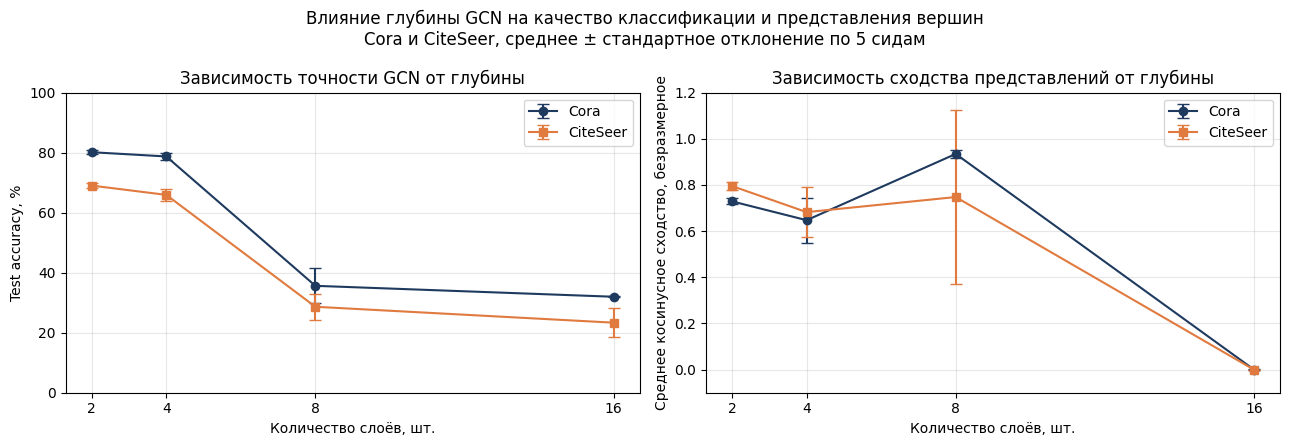

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].errorbar(
    depths, np.array(accs) * 100,
    yerr=np.array(acc_stds) * 100,
    fmt="o-", capsize=4,
    label="Cora", color="#1F3A5F")

ax[0].errorbar(
    depths, np.array(accs_citeseer) * 100,
    yerr=np.array(acc_stds_citeseer) * 100,
    fmt="s-", capsize=4,
    label="CiteSeer", color="#E07A3F")

ax[0].set_title("Зависимость точности GCN от глубины")
ax[0].set_xlabel("Количество слоёв, шт.")
ax[0].set_ylabel("Test accuracy, %")
ax[0].set_xticks(depths)
ax[0].set_ylim(0, 100)
ax[0].legend()
ax[0].grid(alpha=0.3)


ax[1].errorbar(
    depths, sims,
    yerr=sim_stds,
    fmt="o-", capsize=4,
    label="Cora", color="#1F3A5F")

ax[1].errorbar(
    depths, sims_citeseer,
    yerr=sim_stds_citeseer,
    fmt="s-", capsize=4,
    label="CiteSeer", color="#E07A3F")

ax[1].set_title("Зависимость сходства представлений от глубины")
ax[1].set_xlabel("Количество слоёв, шт.")
ax[1].set_ylabel("Среднее косинусное сходство, безразмерное")
ax[1].set_xticks(depths)
ax[1].set_ylim(-0.1, 1.2)
ax[1].legend()
ax[1].grid(alpha=0.3)

fig.suptitle(
    "Влияние глубины GCN на качество классификации и представления вершин\n"
    "Cora и CiteSeer, среднее ± стандартное отклонение по 5 сидам")

plt.tight_layout()
plt.show()

**Вывод:** В эксперименте исследовано влияние глубины GCN (2, 4, 8 и 16 слоёв) на качество классификации и сходство скрытых представлений вершин на датасетах Cora и CiteSeer. Каждая конфигурация обучалась с пятью различными случайными сидами.

Наибольшая точность получена для двухслойных моделей: 80.1 ± 0.7% на Cora и 69.0 ± 0.9% на CiteSeer. При увеличении глубины до 16 слоёв точность снизилась до 32.0 ± 0.2% и 23.3 ± 4.8% соответственно.

Дополнительная диагностика скрытых представлений выявила два механизма деградации:

1. **Over-smoothing.** При многократной агрегации представления вершин становятся похожими друг на друга. Для восьмислойной GCN на Cora среднее косинусное сходство составило 0.934 ± 0.017, что указывает на сближение представлений. Однако в отдельных запусках наблюдалось затухание активаций, поэтому нельзя объяснять падение точности только over-smoothing. На CiteSeer сходство составило 0.748 ± 0.375, что указывает на значительную зависимость результатов от случайной инициализации.

2. **Затухание активаций.** При шестнадцати слоях на обоих датасетах во всех пяти запусках 100% скрытых векторов имели норму меньше $(10^{-8})$. Средние нормы составили $(9.41\times10^{-15})$ для Cora и $(7.31\times10^{-17})$ для CiteSeer. В этом случае близкое к нулю вычисленное косинусное сходство не свидетельствует о разнообразии представлений, поскольку их нормы практически занулились.

Для восьмислойных моделей также наблюдается нестабильность: доля практически нулевых векторов составила 20.0 ± 40.0% на Cora и 24.7 ± 38.7% на CiteSeer. Это подтверждает, что разные запуски глубоких моделей могут демонстрировать различное поведение.

Таким образом, увеличение глубины GCN без residual-связей сопровождается существенным снижением точности классификации. При восьми слоях наблюдаются признаки сближения представлений и нестабильность обучения, а при шестнадцати — выраженное затухание активаций. Для различения этих эффектов необходимо анализировать не только accuracy и косинусное сходство, но и нормы скрытых представлений.

### **Бонус A. Inductive-режим**

Проверяем, умеет ли модель считать векторы для вершин, которых не видела при обучении.

- Отложите «новые» вершины — 1000 вершин стандартного test_mask. Уберите из графа и их самих, и все их рёбра (torch_geometric.utils.subgraph): получится обучающий подграф.
- Inductive: обучите двухслойную модель на MySAGEConv только на подграфе. Затем без переобучения прогоните её по полному графу — новые вершины приходят вместе со своими рёбрами — и посчитайте accuracy на новых вершинах.
- Transductive: обучите ту же модель на полном графе — видны все вершины и рёбра, метки только у обучающих вершин — и посчитайте accuracy на тех же новых вершинах.
- Сведите результат в таблицу: по 5 сидов на режим, среднее ± стандартное отклонение.
- Объясните в 2–3 предложениях, насколько дорого обходится то, что модель не видела новые вершины, и откуда берётся эта разница.

In [21]:
# вершины, которые модель не должна видеть в inductive-режиме
new_mask = data_cora.test_mask

# оставляем все вершины, кроме тестовых
keep_mask = ~new_mask

# удаляем тестовые вершины и все связанные с ними рёбра
edge_index_sub, _ = subgraph(
    subset=keep_mask,
    edge_index=data_cora.edge_index,
    relabel_nodes=True,
    num_nodes=data_cora.num_nodes)

# создаём отдельный объект графа
data_sub = data_cora.clone()

# оставляем признаки и метки только сохранённых вершин
data_sub.x = data_cora.x[keep_mask]
data_sub.y = data_cora.y[keep_mask]

# маски сокращаем до размера подграфа
data_sub.train_mask = data_cora.train_mask[keep_mask]
data_sub.val_mask = data_cora.val_mask[keep_mask]
data_sub.test_mask = data_cora.test_mask[keep_mask]

data_sub.edge_index = edge_index_sub
data_sub.num_nodes = int(keep_mask.sum())

print(f"Полный граф: {data_cora.num_nodes} вершин")
print(f"Обучающий подграф: {data_sub.num_nodes} вершин")
print(f"Новых вершин: {int(new_mask.sum())}")
print(f"Обучающих вершин: {int(data_sub.train_mask.sum())}")

Полный граф: 2708 вершин
Обучающий подграф: 1708 вершин
Новых вершин: 1000
Обучающих вершин: 140


In [22]:
seeds = [42, 123, 456, 789, 2026]
inductive_accs = []

for seed in seeds:
    torch.manual_seed(seed)

    model = GNN(
        in_dim=dataset_cora.num_features,
        hidden=64,
        out_dim=dataset_cora.num_classes,
        layers=2,
        conv=MySAGEConv,
        dropout=0.5)

    # обучаем только на подграфе
    train(model, data_sub)

    # проверяем на полном графе с новыми вершинами
    model.eval()
    with torch.no_grad():
        logits = model(data_cora.x, data_cora.edge_index)

        pred = logits[data_cora.test_mask].argmax(dim=1)
        target = data_cora.y[data_cora.test_mask]

        acc = (pred == target).float().mean().item()

    inductive_accs.append(acc)
    print(f"Seed {seed}: inductive accuracy = {acc:.3f}")

print(
    f"\nInductive: "
    f"{np.mean(inductive_accs):.3f} ± {np.std(inductive_accs):.3f}")

Seed 42: inductive accuracy = 0.773
Seed 123: inductive accuracy = 0.777
Seed 456: inductive accuracy = 0.800
Seed 789: inductive accuracy = 0.792
Seed 2026: inductive accuracy = 0.772

Inductive: 0.783 ± 0.011


In [23]:
transductive_accs = []

for seed in seeds:
    torch.manual_seed(seed)

    model = GNN(
        in_dim=dataset_cora.num_features,
        hidden=64,
        out_dim=dataset_cora.num_classes,
        layers=2,
        conv=MySAGEConv,
        dropout=0.5)

    # обучаем на полном графе
    train(model, data_cora)

    # проверяем на 1000 тестовых вершинах
    model.eval()
    with torch.no_grad():
        logits = model(data_cora.x, data_cora.edge_index)

        pred = logits[data_cora.test_mask].argmax(dim=1)
        target = data_cora.y[data_cora.test_mask]

        acc = (pred == target).float().mean().item()

    transductive_accs.append(acc)
    print(f"Seed {seed}: transductive accuracy = {acc:.3f}")

print(
    f"\nTransductive: "
    f"{np.mean(transductive_accs):.3f} ± {np.std(transductive_accs):.3f}")

Seed 42: transductive accuracy = 0.794
Seed 123: transductive accuracy = 0.792
Seed 456: transductive accuracy = 0.787
Seed 789: transductive accuracy = 0.804
Seed 2026: transductive accuracy = 0.796

Transductive: 0.795 ± 0.006


In [24]:
results = pd.DataFrame({
    "Режим": ["Inductive", "Transductive"],
    "Видела ли модель новые вершины при обучении?": [
        "Нет",
        "Да, но без меток"
    ],
    "Accuracy на новых вершинах, %": [
        f"{np.mean(inductive_accs)*100:.1f} ± {np.std(inductive_accs)*100:.1f}",
        f"{np.mean(transductive_accs)*100:.1f} ± {np.std(transductive_accs)*100:.1f}"
    ]
})

display(results)

,Режим,Видела ли модель новые вершины при обучении?,"Accuracy на новых вершинах, %"
0,Inductive,Нет,78.3 ± 1.1
1,Transductive,"Да, но без меток",79.5 ± 0.6


**Вывод:** В inductive-режиме двухслойная GraphSAGE, обученная без 1000 тестовых вершин и связанных с ними ребер, достигла точности 78.3 ± 1.1%, тогда как в transductive-режиме при обучении на полном графе - 79.5 ± 0.6%. Отсутствие тестовых вершин при обучении снизило точность всего на 1.2 п.п., так как модель не могла использовать их признаки и связи при формировании представлений обучающих вершин. При этом GraphSAGE успешно обобщает знания на новые вершины благодаря агрегации признаков их соседей при инференсе.

### **Бонус B. Сколько разметки нужно графу**

- Постройте зависимость accuracy от доли размеченных вершин: 1%, 5%, 20%, 60%.
- На одном графике — GCN и MLP.
- Ответьте: при какой доле разметки преимущество графа исчезает и почему.

In [25]:
fractions = [0.01, 0.05, 0.20, 0.60]
seeds = [42, 123, 456, 789, 2026]

pool_mask = ~(data_cora.val_mask | data_cora.test_mask)
pool_idx = pool_mask.nonzero(as_tuple=True)[0]

print(f"Всего вершин: {data_cora.num_nodes}")
print(f"Доступно для обучения: {pool_idx.numel()}")

for fraction in fractions:
    n_train = max(1, round(fraction * pool_idx.numel()))
    print(f"{fraction:.0%} разметки: {n_train} вершин")

Всего вершин: 2708
Доступно для обучения: 1208
1% разметки: 12 вершин
5% разметки: 60 вершин
20% разметки: 242 вершин
60% разметки: 725 вершин


In [26]:
gcn_accs = []
mlp_accs = []

gcn_stds = []
mlp_stds = []

for fraction in fractions:
    fraction_gcn_accs = []
    fraction_mlp_accs = []

    for seed in seeds:
        torch.manual_seed(seed)

        # выбираем размеченные вершины
        n_train = max(1, round(fraction * pool_idx.numel()))
        selected_idx = pool_idx[
            torch.randperm(pool_idx.numel(), device=pool_idx.device)[:n_train]]

        # создаем граф с новой обучающей маской
        data_fraction = data_cora.clone()
        data_fraction.train_mask = torch.zeros_like(data_cora.train_mask)
        data_fraction.train_mask[selected_idx] = True

        # GCN
        torch.manual_seed(seed)
        gcn = GNN(
            in_dim=dataset_cora.num_features,
            hidden=64,
            out_dim=dataset_cora.num_classes,
            layers=2,
            conv=MyGCNConv,
            dropout=0.5)

        gcn_acc = train(gcn, data_fraction)
        fraction_gcn_accs.append(gcn_acc)

        # MLP
        torch.manual_seed(seed)
        mlp = MLP(
            in_dim=dataset_cora.num_features,
            hidden=64,
            out_dim=dataset_cora.num_classes,
            layers=2,
            dropout=0.5)

        mlp_acc = train(mlp, data_fraction)
        fraction_mlp_accs.append(mlp_acc)

    gcn_accs.append(np.mean(fraction_gcn_accs))
    mlp_accs.append(np.mean(fraction_mlp_accs))

    gcn_stds.append(np.std(fraction_gcn_accs))
    mlp_stds.append(np.std(fraction_mlp_accs))

    print(
        f"{fraction:.0%} разметки: "
        f"GCN {np.mean(fraction_gcn_accs):.3f} ± {np.std(fraction_gcn_accs):.3f}, "
        f"MLP {np.mean(fraction_mlp_accs):.3f} ± {np.std(fraction_mlp_accs):.3f}")

1% разметки: GCN 0.490 ± 0.077, MLP 0.347 ± 0.024
5% разметки: GCN 0.725 ± 0.016, MLP 0.484 ± 0.025
20% разметки: GCN 0.828 ± 0.011, MLP 0.632 ± 0.015
60% разметки: GCN 0.862 ± 0.006, MLP 0.716 ± 0.007


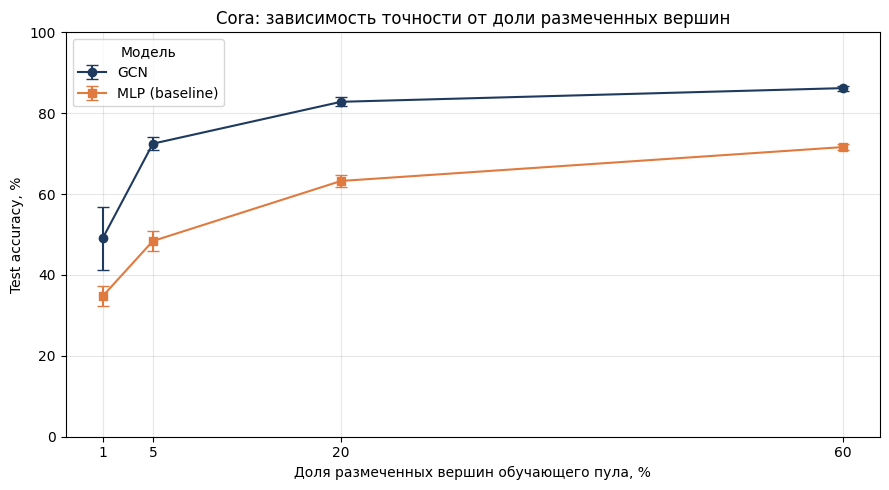

In [27]:
fractions_pct = np.array(fractions) * 100

plt.figure(figsize=(9, 5))

plt.errorbar(
    fractions_pct,
    np.array(gcn_accs) * 100,
    yerr=np.array(gcn_stds) * 100,
    fmt="o-",
    capsize=4,
    label="GCN",
    color="#1F3A5F")

plt.errorbar(
    fractions_pct,
    np.array(mlp_accs) * 100,
    yerr=np.array(mlp_stds) * 100,
    fmt="s-",
    capsize=4,
    label="MLP (baseline)",
    color="#E07A3F")

plt.title("Cora: зависимость точности от доли размеченных вершин")
plt.xlabel("Доля размеченных вершин обучающего пула, %")
plt.ylabel("Test accuracy, %")
plt.xticks(fractions_pct)
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend(title="Модель")

plt.tight_layout()
plt.show()

**Вывод:** При увеличении доли размеченных вершин точность обеих моделей возрастает: GCN — с 49.0 ± 7.7% до 86.2 ± 0.6%, MLP — с 34.7 ± 2.4% до 71.6 ± 0.7%.

Преимущество графовой модели не исчезает ни при одной из исследованных долей разметки (1%, 5%, 20%, 60%). Наибольший выигрыш GCN наблюдается при 5% разметки (+24.1 п.п.), а при 60% он сокращается до 14.6 п.п.

Это объясняется тем, что GCN использует не только признаки размеченных вершин, но и структуру графа, агрегируя информацию от соседей. При увеличении количества разметки MLP получает больше обучающих примеров и улучшает качество, однако в данном эксперименте не догоняет GCN, поскольку не использует связи между вершинами.